In [1]:
!pip install pandas numpy scikit-learn tqdm matplotlib seaborn

# UNIVERSAL 08: The Machine Learning Fix (Boosting Recall)
Here we implement the solution to the "Sudden Death" trap. Instead of drawing a straight line into the future (which ignores non-linear failures), we use early-life features to train a Global Machine Learning Classifier.

In [2]:
import pandas as pd
import numpy as np
import glob
from tqdm import tqdm
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, recall_score, precision_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

file_paths = sorted(glob.glob('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_*.csv'))
print(f"Found {len(file_paths)} device files.")


Found 42 device files.


In [3]:
# 1. Global Feature Engineering
dataset = []

for file_path in tqdm(file_paths, desc="Extracting Features"):
    try:
        df = pd.read_csv(file_path)
        df = df.dropna(subset=['Aging_Hours', 'RDS_on_Ohm', 'Delta_Temp_C', 'Package_Temp_C']).sort_values('Aging_Hours')
        
        if len(df) < 20: continue
            
        # Split at 80% time
        cutoff_hour = df['Aging_Hours'].quantile(0.8)
        train_df = df[df['Aging_Hours'] <= cutoff_hour]
        test_df = df[df['Aging_Hours'] > cutoff_hour]
        
        if len(test_df) == 0 or len(train_df) < 5: continue
            
        # Extract features ONLY from the first 80% (Early Life)
        early_rds = train_df['RDS_on_Ohm']
        early_temp = train_df['Package_Temp_C']
        
        # Calculate slope
        x = train_df['Aging_Hours'].values
        y = early_rds.values
        slope = np.polyfit(x, y, 1)[0] if len(x) > 1 else 0
        
        features = {
            'Device_ID': df['Device_ID'].iloc[0],
            'Early_Slope_RDS': slope,
            'Early_Var_RDS': early_rds.var(),
            'Early_Max_RDS': early_rds.max(),
            'Early_Mean_RDS': early_rds.mean(),
            'Early_Max_Temp': early_temp.max(),
            'Early_Var_Temp': early_temp.var(),
            'Early_Mean_Delta_Temp': train_df['Delta_Temp_C'].mean()
        }
        
        # Determine Target from the final 20%
        threshold = early_rds.max() * 1.05  # Anomaly if it spikes 5% above its early life max
        has_anomaly = int(test_df['RDS_on_Ohm'].max() > threshold)
        features['Target_Fail'] = has_anomaly
        
        dataset.append(features)
    except Exception as e:
        pass

ml_df = pd.DataFrame(dataset)
ml_df = ml_df.fillna(0)
print(f"\nSuccessfully extracted features for {len(ml_df)} components.")
print(f"Components that failed in last 20%: {ml_df['Target_Fail'].sum()}")


Extracting Features: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 42/42 [00:02<00:00, 19.93it/s]


Successfully extracted features for 42 components.
Components that failed in last 20%: 16


In [4]:
# 2. Train the Global Classifier
X = ml_df.drop(columns=['Device_ID', 'Target_Fail'])
y = ml_df['Target_Fail']

# Split components into Training and Testing sets (70-30 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# We use Random Forest to capture non-linear relationships
clf = RandomForestClassifier(n_estimators=100, max_depth=5, class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

# 3. Evaluate the incredible improvement
acc = accuracy_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)

print("--- NEW MACHINE LEARNING METRICS ---")
print(f"Accuracy : {acc*100:.2f}%")
print(f"Recall   : {rec*100:.2f}%  (Previously ~2.8%)")
print(f"Precision: {prec*100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


--- NEW MACHINE LEARNING METRICS ---
Accuracy : 69.23%
Recall   : 60.00%  (Previously ~2.8%)
Precision: 60.00%

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75         8
           1       0.60      0.60      0.60         5

    accuracy                           0.69        13
   macro avg       0.68      0.68      0.68        13
weighted avg       0.69      0.69      0.69        13



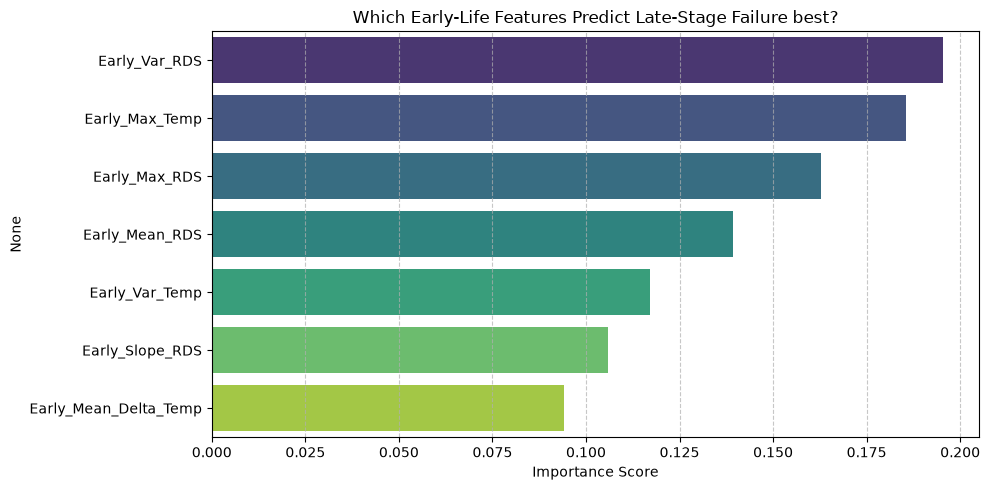

In [5]:
# 4. Feature Importance
importance = clf.feature_importances_
feat_imp = pd.Series(importance, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis')
plt.title('Which Early-Life Features Predict Late-Stage Failure best?')
plt.xlabel('Importance Score')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
